# Part 2: Predicting Book Bestseller Status with Logistic Regression

**Module:** Programming for Data Analytics 2 (PDAN8412/w)  
**Student Number:** ST10356048  
**Dataset:** Amazon Kindle Books Dataset 2023

## Introduction

A book publisher wants to know whether it is possible to identify books that are likely to become bestsellers. My task is to investigate this problem by building a Logistic Regression algorithm from scratch.

I selected the Amazon Kindle Books Dataset 2023 (asaniczka, 2023), which contains book information alongside an indicator showing whether each title carried Amazon's bestseller designation at collection time. I will first evaluate the dataset, examine the factors associated with bestseller status, and select suitable features before developing and testing the model.

Although the publisher's question concerns future success, the available data records bestseller status at the time of collection. I will therefore use it to investigate bestseller classification while recognising that the results cannot establish future sales performance.

In [29]:
import os
import sys
from pathlib import Path

import numpy as np
from pyspark.sql import SparkSession

# Keep the results reproducible.
SEED = 42
np.random.seed(SEED)

# Locate the dataset and prepare the output directory.
PROJECT_ROOT = Path.cwd().resolve().parent
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "kindle_data-v2.csv"
FIGURE_DIR = PROJECT_ROOT / "outputs" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

assert DATA_PATH.is_file(), "The original dataset could not be found."

# Start Spark using the local machine.
os.environ.setdefault("SPARK_LOCAL_IP", "127.0.0.1")

spark = (
    SparkSession.builder
    .appName("PDAN8412 Part 2")
    .master("local[2]")
    .config("spark.driver.host", "127.0.0.1")
    .config("spark.driver.bindAddress", "127.0.0.1")
    .config("spark.ui.enabled", "false")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("ERROR")

spark.conf.set("spark.sql.execution.arrow.pyspark.enabled", "false")

print("Python:", sys.version.split()[0])
print("Spark:", spark.version)
print("Dataset found:", DATA_PATH.name)

Python: 3.12.14
Spark: 4.2.0
Dataset found: kindle_data-v2.csv


## 1. Dataset Evaluation and Suitability

Before attempting to predict bestseller status, I need to establish whether the dataset contains enough reliable information to answer the publisher's question.

I selected the Amazon Kindle Books Dataset 2023 because it provides book characteristics alongside an existing bestseller indicator. However, having a suitable target does not necessarily mean the data is ready for modelling.

I will examine its structure, class distribution and data quality, paying particular attention to issues that could affect the reliability of the model.

### 1.1 Dataset Structure and Target Variable

I begin by checking the dataset's size, available features and bestseller labels. This is important because the model needs a reliable binary target and suitable book characteristics from which to learn.

I also check how Spark interprets the CSV file, particularly quotation marks within book titles, to avoid introducing errors before the analysis begins.

In [2]:
books = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .option("escape", '"')
    .option("mode", "FAILFAST")
    .csv(str(DATA_PATH))
)

print(f"Records: {books.count():,}")
print(f"Columns: {len(books.columns)}")

books.printSchema()
books.groupBy("isBestSeller").count().orderBy("isBestSeller").show()

Records: 133,102
Columns: 16
root
 |-- asin: string (nullable = true)
 |-- title: string (nullable = true)
 |-- author: string (nullable = true)
 |-- soldBy: string (nullable = true)
 |-- imgUrl: string (nullable = true)
 |-- productURL: string (nullable = true)
 |-- stars: double (nullable = true)
 |-- reviews: integer (nullable = true)
 |-- price: double (nullable = true)
 |-- isKindleUnlimited: boolean (nullable = true)
 |-- category_id: integer (nullable = true)
 |-- isBestSeller: boolean (nullable = true)
 |-- isEditorsPick: boolean (nullable = true)
 |-- isGoodReadsChoice: boolean (nullable = true)
 |-- publishedDate: date (nullable = true)
 |-- category_name: string (nullable = true)

+------------+------+
|isBestSeller| count|
+------------+------+
|       false|130866|
|        true|  2236|
+------------+------+



**Findings**

The dataset contains 133,102 books and 16 columns, comfortably exceeding the assignment's minimum of 10,000 records. After correcting how Spark reads quotation marks in the CSV, the fields were imported with the appropriate data types.

Only 2,236 books (1.68%) are labelled as bestsellers, compared with 130,866 non-bestsellers. This is an important challenge: a model that always predicts "not a bestseller" could achieve 98.32% accuracy without identifying a single bestseller.

For the publisher, identifying potential bestsellers matters more than simply achieving high accuracy. I will therefore pay particular attention to precision, recall and F1-score when evaluating the model.

### 1.2 Data Quality

The dataset is large enough for the assignment, but its size alone does not guarantee reliable results.

I will check for missing information, duplicate records and unusual values before deciding which book characteristics are suitable for modelling. These checks should also help me identify potential problems that could influence the model's predictions.

#### Missing Values

I started by checking how much information is missing from each column. This will help me decide whether certain features need cleaning, special treatment or exclusion.

In [3]:
from pyspark.sql import functions as F

missing = books.select([
    F.count(
        F.when(
            F.col(c).isNull() | (F.trim(F.col(c).cast("string")) == ""), 1
        )
    ).alias(c)
    for c in books.columns
]).first().asDict()

for column, count in sorted(missing.items(), key=lambda x: x[1], reverse=True):
    if count:
        print(f"{column}: {count:,}")

publishedDate: 49,016
soldBy: 9,233
author: 425


**Findings**

Most columns are complete, although `publishedDate` is missing for 36.83% of books. There are also smaller gaps in `soldBy` (6.94%) and `author` (0.32%).

The missing publication dates may limit the usefulness of this feature when identifying bestsellers. I will leave the data unchanged for now and consider how to handle these gaps when preparing the model.

#### Duplicate Records

I also checked whether books appear more than once in the dataset. I used the Amazon Standard Identification Number (`asin`) to identify repeated book listings and checked for completely identical records.

This matters because duplicate observations could give certain books more influence during model training.

In [4]:
total_books = books.count()

print("Repeated ASINs:", total_books - books.select("asin").distinct().count())
print("Duplicate rows:", total_books - books.dropDuplicates().count())

Repeated ASINs: 0
Duplicate rows: 0


**Findings**

I found no repeated ASINs or identical records. This suggests that the dataset does not contain straightforward duplicates that could distort the analysis.

However, different editions of the same book may have separate ASINs. I will consider this when splitting the data to avoid evaluating the model on books it may have effectively encountered during training.

#### Unusual Values

Some fields may be complete but still contain values that need careful interpretation. I will check prices, ratings, review counts and publication dates for unusual observations.

This will help me understand whether these features could provide reliable information about bestseller status before deciding how to use them.

In [5]:
checks = books.agg(
    F.count_if(F.col("price") == 0).alias("Zero prices"),
    F.count_if(F.col("stars") == 0).alias("Zero ratings"),
    F.count_if(F.col("reviews") == 0).alias("Zero reviews"),
    F.count_if(F.col("price") < 0).alias("Negative prices"),
    F.count_if(~F.col("stars").between(0, 5)).alias("Ratings outside 0–5"),
    F.count_if(F.col("reviews") < 0).alias("Negative reviews"),
    F.count_if(F.year("publishedDate") > 2023).alias("Dates after 2023")
).first().asDict()

for item, count in checks.items():
    print(f"{item}: {count:,}")

Zero prices: 4,066
Zero ratings: 3,182
Zero reviews: 64,670
Negative prices: 0
Ratings outside 0–5: 0
Negative reviews: 0
Dates after 2023: 1


**Findings**

Almost half of the books have zero recorded reviews (48.59%), while 3.05% have zero prices and 2.39% have zero-star ratings. These values may represent unavailable information rather than genuine zeros, so I cannot assume that every recorded value is reliable.

I also found one publication date after 2023, but no negative prices, negative review counts or ratings outside the expected range.

These findings suggest that some features will need careful treatment. I will consider their reliability and relevance before using them to train the model.

### 1.3 Overall Dataset Suitability

The dataset is suitable for this classification task because it contains more than 10,000 records, an existing binary target and several book characteristics that could help distinguish bestsellers from other titles.

However, two limitations are particularly important.

First, only 1.68% of books are labelled as bestsellers. As Saito and Rehmsmeier (2015) explain, precision-recall analysis is particularly useful when positive cases are rare. I will therefore evaluate the model using more than accuracy alone.

Second, some features may reveal information that the publisher would not have when making an early prediction. Reviews, ratings and editorial endorsements could reflect popularity after publication. Kaufman et al. (2012) explain that using information unavailable at prediction time can introduce data leakage.

I will consider these limitations when planning the analysis and selecting features. The dataset provides a suitable foundation for testing Logistic Regression, but its results must be interpreted as classification of recorded Amazon bestseller status, not proof of future sales success.

## 2. Analysis Plan

The publisher wants to identify books that may become bestsellers. Before building the model, I need a clear approach that accounts for the limitations identified during the dataset evaluation.

I will use Logistic Regression to classify Amazon bestseller status, while recognising that the dataset does not contain future sales outcomes.

The following plan outlines how I will investigate the data, develop the algorithm and evaluate its usefulness.

| Stage | Planned approach |
|---|---|
| **1. Exploratory Data Analysis** | Use PySpark to examine bestseller patterns across book categories, prices and publication dates. I will also investigate missing information and unusual values to understand which features may be useful. |
| **2. Feature Selection** | Select relevant book characteristics using the EDA findings. I will prioritise information that could reasonably be available when assessing a book and exclude identifiers, reviews, ratings and endorsements that may introduce leakage. |
| **3. Model Training** | Prepare the selected features and implement Logistic Regression from scratch using NumPy. I will use gradient descent to minimise binary cross-entropy and compare a baseline model with regularised and class-weighted versions. |
| **4. Evaluation** | Separate the data into training, validation and test sets. I will assess performance using precision, recall, F1-score, average precision, ROC-AUC and a confusion matrix. |
| **5. Reporting** | Explain the EDA findings, feature decisions, model implementation, evaluation results and limitations, with recommendations relevant to the publisher. |

### Additional Considerations

**Data leakage:** According to Kaufman, et al. (2012), information that would not legitimately be available when making a prediction can lead to misleading results. I will therefore exclude potential outcome-related signals from the main model.

**Class imbalance:** Only 1.68% of the books are labelled as bestsellers. He and Garcia (2009) explain the difficulties associated with imbalanced learning, while Saito and Rehmsmeier (2015) highlight the value of precision-recall analysis in these circumstances.

**Reliable evaluation:** I will aim for a 70:15:15 training, validation and test split, keeping related books together where possible. Preprocessing will be fitted using training data only, and the test set will remain untouched until the final evaluation.

This approach should allow me to build a manageable, reproducible model and assess its performance without overstating what the available data can tell the publisher.

## 3. Exploratory Data Analysis

The next step is to investigate which book characteristics might help distinguish bestsellers from other titles.

I will focus on patterns that can inform feature selection and model training. Before examining these relationships, I will check for related book listings and separate the data so that the final test set remains independent of my modelling decisions.

### 3.1 Related Book Listings

Although I found no duplicate ASINs, different editions of the same book may appear under separate identifiers.

I will check for repeated title-author combinations to identify potentially related listings. Keeping these records together during data splitting should help produce a fairer evaluation.

In [6]:
# Identify books sharing the same title and author.
title = F.regexp_replace(F.lower("title"), r"[^a-z0-9]", "")
author = F.regexp_replace(F.lower("author"), r"[^a-z0-9]", "")

books = books.withColumn(
    "book_group",
    F.when(
        (F.length(title) > 0) & (F.length(author) > 0),
        F.concat_ws("|", author, title)
    ).otherwise(F.col("asin"))
)

related = books.groupBy("book_group").count().filter("count > 1")

related.agg(
    F.count("*").alias("Related groups"),
    F.sum("count").alias("Related listings"),
    F.max("count").alias("Largest group")
).show()

+--------------+----------------+-------------+
|Related groups|Related listings|Largest group|
+--------------+----------------+-------------+
|          1019|            2063|            6|
+--------------+----------------+-------------+



**Findings**

I identified 1,019 groups containing repeated title-author combinations, covering 2,063 listings (1.55% of the dataset). The largest group contains six listings.

Although these are not necessarily duplicate books, separating related listings across training and testing could make the model appear more effective than it really is.

I will therefore keep these groups together when dividing the data. This should provide a fairer assessment of how the model performs on books it has not encountered during training.

### 3.2 Preparing the Data for Independent Evaluation

Before exploring which features are associated with bestseller status, I will reserve separate validation and test sets.

I will use approximately 70% of the data for training, 15% for validation and 15% for testing. Records sharing the same title-author group will remain together to reduce the risk of information leakage.

The following EDA will use the training data only, leaving the validation and test sets available for evaluating the model later.

In [7]:
# Assign related books to the same dataset split.
bucket = F.pmod(F.xxhash64("book_group", F.lit(SEED)), F.lit(100))

books = books.withColumn(
    "split",
    F.when(bucket < 70, "train")
     .when(bucket < 85, "validation")
     .otherwise("test")
)

books.groupBy("split").agg(
    F.count("*").alias("books"),
    F.sum(F.col("isBestSeller").cast("int")).alias("bestsellers"),
    F.round(F.avg(F.col("isBestSeller").cast("int")) * 100, 2).alias("bestseller_rate")
).orderBy("split").show()

+----------+-----+-----------+---------------+
|     split|books|bestsellers|bestseller_rate|
+----------+-----+-----------+---------------+
|      test|19684|        338|           1.72|
|     train|93390|       1571|           1.68|
|validation|20028|        327|           1.63|
+----------+-----+-----------+---------------+



**Findings**

The split produced 93,390 training records, 20,028 validation records and 19,684 test records. Bestseller rates remain close to the original 1.68%, with sufficient positive cases in each partition.

I will use the training set for the remaining EDA and model development. The validation set will support model selection, while the test set will remain untouched until the final evaluation.

In [8]:
shared_groups = (
    books.groupBy("book_group")
    .agg(F.countDistinct("split").alias("n_splits"))
    .filter("n_splits > 1")
    .count()
)

print("Groups appearing in multiple splits:", shared_groups)
assert shared_groups == 0

Groups appearing in multiple splits: 0


### 3.3 Book Categories and Bestseller Status

A book's category may offer useful information when a publisher is assessing its potential. Yucesoy et al. (2018) found that bestseller representation differed across genres in their study of US hardcover books.

I will examine whether a similar relationship appears in the Kindle dataset by comparing the number of books and the bestseller rate across categories.

I will use the training data only and consider category sizes alongside their bestseller rates to avoid drawing conclusions from very small groups.

In [9]:
train_books = books.filter(F.col("split") == "train")

category_summary = (
    train_books.groupBy("category_name")
    .agg(
        F.count("*").alias("books"),
        F.sum(F.col("isBestSeller").cast("int")).alias("bestsellers")
    )
    .withColumn(
        "bestseller_rate",
        F.round(100 * F.col("bestsellers") / F.col("books"), 2)
    )
)

category_summary.orderBy(F.desc("books")).show(12, truncate=False)

+----------------------------+-----+-----------+---------------+
|category_name               |books|bestsellers|bestseller_rate|
+----------------------------+-----+-----------+---------------+
|Mystery, Thriller & Suspense|4377 |72         |1.64           |
|Engineering & Transportation|4305 |45         |1.05           |
|Science & Math              |4136 |126        |3.05           |
|Parenting & Relationships   |4108 |50         |1.22           |
|Children's eBooks           |4070 |107        |2.63           |
|Teen & Young Adult          |4067 |111        |2.73           |
|Foreign Language            |4053 |24         |0.59           |
|Travel                      |3911 |69         |1.76           |
|LGBTQ+ eBooks               |3879 |12         |0.31           |
|Computers & Technology      |3866 |59         |1.53           |
|Crafts, Hobbies & Home      |3819 |70         |1.83           |
|Biographies & Memoirs       |3813 |99         |2.6            |
+------------------------

**Findings**

Bestseller rates differ noticeably across the categories examined. Science & Math has a rate of 3.05%, followed by Teen & Young Adult (2.73%) and Children's eBooks (2.63%). All three exceed the training dataset's overall rate of 1.68%.

In contrast, Foreign Language (0.59%) and LGBTQ+ eBooks (0.31%) have considerably lower rates.

These differences suggest that category could be a useful predictor. However, the table only shows the 12 largest categories, so I will examine the complete distribution before drawing conclusions about its value to the model.

#### Comparing Bestseller Rates Across Categories

To see whether these differences extend beyond the largest categories, I will compare bestseller rates across all categories.

I will also check category sizes, since a high bestseller rate based on very few books could be misleading.

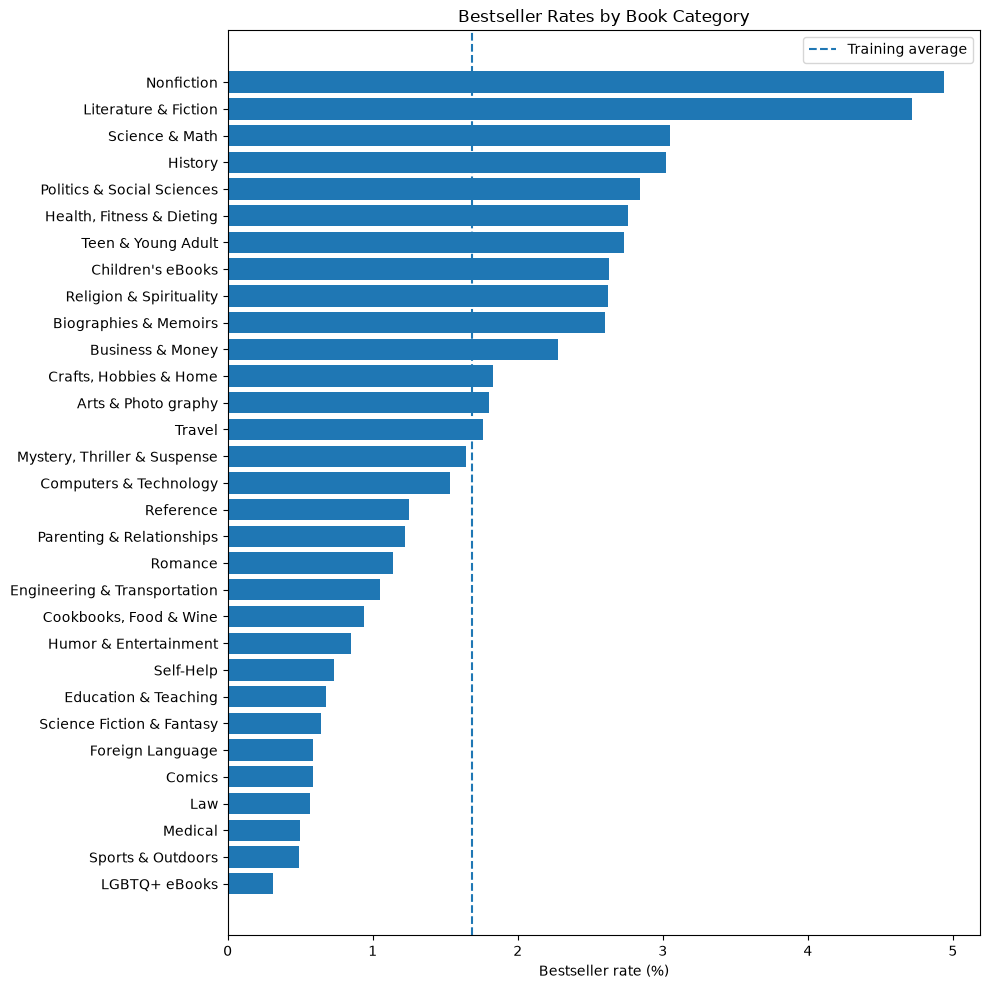

Categories: 31
Smallest category: 337 books


In [10]:
import matplotlib.pyplot as plt

category_plot = category_summary.toPandas().sort_values("bestseller_rate")
average_rate = 100 * train_books.agg(
    F.avg(F.col("isBestSeller").cast("int"))
).first()[0]

fig, ax = plt.subplots(figsize=(10, 10))

ax.barh(category_plot["category_name"], category_plot["bestseller_rate"])
ax.axvline(average_rate, linestyle="--", label="Training average")

ax.set(
    xlabel="Bestseller rate (%)",
    title="Bestseller Rates by Book Category"
)
ax.legend()

plt.tight_layout()
fig.savefig(PROJECT_ROOT / "outputs/figures/category_rates.png", dpi=180)
plt.show()

print("Categories:", len(category_plot))
print("Smallest category:", category_plot["books"].min(), "books")

**Findings**

The training data contains 31 categories, each with at least 337 books. Among the largest categories, bestseller rates range from 0.31% for LGBTQ+ eBooks to 3.05% for Science & Math, compared with the overall rate of 1.68%.

These differences suggest that category may help distinguish bestsellers from other books. However, they show an association rather than proof that a particular category leads to commercial success.

I will retain category as a candidate feature and assess its value when evaluating the model.

### 3.4 Book Prices and Bestseller Status

Price is a characteristic that publishers can influence, making it worth investigating.

Schmidt-Stölting, Blömeke and Clement (2011) examined factors associated with commercial book success in the German print market. Although their findings cannot be applied directly to Kindle books, they provide a useful reason to investigate book characteristics.

I will compare recorded prices between bestsellers and non-bestsellers, focusing on typical prices and unusually high values. Since the dataset does not confirm original selling prices, I will interpret the findings as marketplace associations rather than evidence that price causes bestseller success.

In [11]:
price_summary = (
    train_books.groupBy("isBestSeller")
    .agg(
        F.count("*").alias("books"),
        F.round(F.avg("price"), 2).alias("mean_price"),
        F.round(F.expr("percentile_approx(price, 0.5)"), 2).alias("median_price"),
        F.round(F.expr("percentile_approx(price, 0.9)"), 2).alias("p90_price"),
        F.round(F.max("price"), 2).alias("max_price")
    )
)

price_summary.orderBy("isBestSeller").show()

+------------+-----+----------+------------+---------+---------+
|isBestSeller|books|mean_price|median_price|p90_price|max_price|
+------------+-----+----------+------------+---------+---------+
|       false|91819|     15.24|        9.99|    30.63|    682.0|
|        true| 1571|      7.56|        5.99|    14.99|     66.0|
+------------+-----+----------+------------+---------+---------+



**Findings**

Bestsellers generally have lower recorded prices, with a median of 5.99 compared with 9.99 for non-bestsellers. The difference also appears at the 90th percentile, suggesting that unusually expensive books are not the only explanation.

Price therefore appears worth investigating as a predictor. However, these are recorded marketplace prices, which may have changed since publication. I will consider this limitation when selecting features and interpreting the model.

### 3.5 Publication Dates and Bestseller Status

Publication timing may also be relevant to a book's bestseller status. However, my initial checks showed that more than a third of publication dates are missing.

I will compare publication-date coverage between bestsellers and non-bestsellers, along with their typical publication years. This should help me decide whether publication timing is reliable enough to consider during modelling.

In [12]:
date_summary = (
    train_books.groupBy("isBestSeller")
    .agg(
        F.count("publishedDate").alias("available_dates"),
        F.round(
            100 * F.avg(F.col("publishedDate").isNull().cast("int")), 2
        ).alias("missing_pct"),
        F.expr(
            "percentile_approx(year(publishedDate), 0.5)"
        ).alias("median_year")
    )
)

date_summary.orderBy("isBestSeller").show()

+------------+---------------+-----------+-----------+
|isBestSeller|available_dates|missing_pct|median_year|
+------------+---------------+-----------+-----------+
|       false|          57954|      36.88|       2019|
|        true|            950|      39.53|       2021|
+------------+---------------+-----------+-----------+



**Findings**

Among books with available dates, bestsellers have a median publication year of 2021, compared with 2019 for non-bestsellers. This suggests that publication timing may help distinguish the two groups.

However, publication dates are missing for 39.53% of bestsellers and 36.88% of non-bestsellers. I will retain publication year as a candidate feature, but its missing values will need careful treatment during model preparation.

### 3.6 Kindle Unlimited and Bestseller Status

Kindle Unlimited availability may also be relevant to the publisher's decisions.

According to Amazon Kindle Direct Publishing (n.d.), KDP Select enrolment makes eligible Kindle books available through Kindle Unlimited. However, the programme status recorded in this dataset may not reflect the book's original publication arrangements.

I will compare bestseller rates between participating and non-participating books to determine whether subscription availability is worth considering as a predictor.

+-----------------+-----+-----------+---------------+
|isKindleUnlimited|books|bestsellers|bestseller_rate|
+-----------------+-----+-----------+---------------+
|            false|68183|        537|           0.79|
|             true|25207|       1034|            4.1|
+-----------------+-----+-----------+---------------+



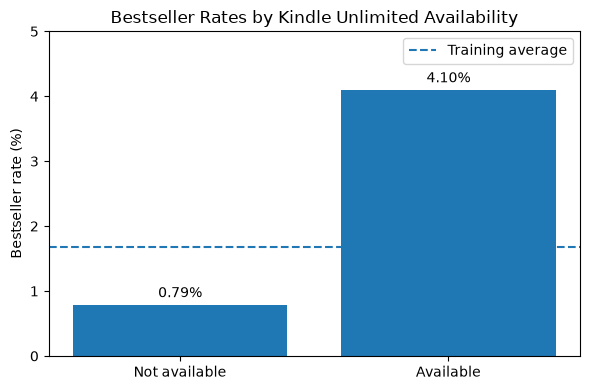

In [13]:
kindle_summary = (
    train_books.groupBy("isKindleUnlimited")
    .agg(
        F.count("*").alias("books"),
        F.sum(F.col("isBestSeller").cast("int")).alias("bestsellers")
    )
    .withColumn(
        "bestseller_rate",
        F.round(100 * F.col("bestsellers") / F.col("books"), 2)
    )
)

kindle_summary.orderBy("isKindleUnlimited").show()

# Compare bestseller rates visually.
rates = [
    row["bestseller_rate"]
    for row in kindle_summary.orderBy("isKindleUnlimited").collect()
]

fig, ax = plt.subplots(figsize=(6, 4))

bars = ax.bar(["Not available", "Available"], rates)
ax.bar_label(bars, fmt="%.2f%%", padding=3)

ax.axhline(
    average_rate,
    linestyle="--",
    label="Training average"
)

ax.set(
    title="Bestseller Rates by Kindle Unlimited Availability",
    ylabel="Bestseller rate (%)",
    ylim=(0, 5)
)
ax.legend()

plt.tight_layout()
fig.savefig(
    PROJECT_ROOT / "outputs/figures/kindle_unlimited_rates.png",
    dpi=180
)
plt.show()

**Findings**

Books available through Kindle Unlimited have a bestseller rate of 4.10%, compared with 0.79% for other books. Although they represent approximately 27% of the training data, they account for 65.8% of its bestsellers.

This is one of the strongest associations observed so far. However, Kindle Unlimited participation may change after publication, and the difference does not establish that subscription availability causes bestseller success.

I will consider Kindle Unlimited as a candidate feature, while recognising that its usefulness for early predictions depends on when the information became available.

### 3.7 EDA Summary and Modelling Implications

The EDA identified several characteristics associated with bestseller status. Category, price, publication year and Kindle Unlimited availability all showed differences between bestsellers and non-bestsellers.

These findings help narrow down the features worth investigating, but their predictive value still needs to be tested.

| Feature | EDA finding | Implication for modelling |
|---|---|---|
| Category | Bestseller rates vary across genres. | Retain as a candidate categorical feature. |
| Price | Bestsellers generally have lower recorded prices. | Consider as a numerical feature, subject to its availability at prediction time. |
| Publication year | Bestsellers with recorded dates tend to be newer. | Consider the year alongside its substantial missingness. |
| Kindle Unlimited | Bestseller rates are considerably higher among participating books. | Investigate its predictive value while accounting for possible timing issues. |
| Reviews, ratings and endorsements | These may reflect popularity after publication. | Exclude from the primary model to reduce leakage risk. |

The main challenge remains the small proportion of bestsellers. I will therefore focus on identifying positive cases rather than relying on overall accuracy.

In the next stage, I will prepare the selected features, handle missing values and ensure that preprocessing is learned from the training data only.

I will also distinguish between features suitable for early assessment and those that describe a book's position in the marketplace at the time of collection.

## 4. Feature Selection and Preparation

The EDA showed that category, price, publication year and Kindle Unlimited availability are associated with bestseller status. However, these relationships do not necessarily mean that every feature is suitable for prediction.

I need to consider when the information would be available to the publisher, how reliable it is and whether it could introduce data leakage.

I will use these considerations to select suitable predictors before preparing the training, validation and test sets for Logistic Regression.

### 4.1 Selecting the Features

The EDA identified four characteristics worth investigating: category, price, publication year and Kindle Unlimited availability.

I will begin with these features because they showed differences between bestsellers and other books, while remaining straightforward to interpret.

Following the principles discussed by Kuhn and Johnson (2019), I will keep the feature set focused on the modelling problem rather than including every available column.

I will exclude reviews, ratings and editorial endorsements because they may reflect popularity after publication. According to Kaufman et al. (2012), using information that would not legitimately be available when making a prediction can produce misleading results.

Price and Kindle Unlimited status also require caution because their values may have changed since publication. My initial model will therefore classify recorded bestseller status rather than claim to predict future sales.

I will now extract the selected features and check whether they require any preparation before training.

In [14]:
# Keep only the information needed for modelling.
model_data = books.select(
    "split",
    "category_name",
    "price",
    F.year("publishedDate").alias("publication_year"),
    F.col("isKindleUnlimited").cast("int").alias("kindle_unlimited"),
    F.col("isBestSeller").cast("int").alias("target")
)

# Check missing values in the training features.
features = [
    "category_name", "price", "publication_year",
    "kindle_unlimited", "target"
]

model_data.filter("split = 'train'").select(
    [F.count_if(F.col(c).isNull()).alias(c) for c in features]
).show()

+-------------+-----+----------------+----------------+------+
|category_name|price|publication_year|kindle_unlimited|target|
+-------------+-----+----------------+----------------+------+
|            0|    0|           34486|               0|     0|
+-------------+-----+----------------+----------------+------+



**Findings**

Of the selected features, only publication year contains missing values, affecting approximately 37% of the training records.

Removing these books would discard a substantial amount of data. I will instead replace missing years with the training-set median and add an indicator showing which dates were unavailable. This preserves the records without pretending that the estimated years are the actual publication dates.

### 4.2 Preparing the Features

Logistic Regression requires numerical inputs, so I need to encode book categories and place numerical features on comparable scales.

I will use one-hot encoding for categories, a logarithmic transformation for prices and median imputation for missing publication years. I will then standardise the numerical features to support gradient descent.

Following the data leakage precautions discussed by Kaufman et al. (2012), I will learn the preprocessing parameters from the training set only and apply the same transformations to the validation and test sets.

In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Prepare the features before converting them to NumPy.
model_data = (
    model_data
    .withColumn("log_price", F.log1p("price"))
    .withColumn(
        "year_missing",
        F.col("publication_year").isNull().cast("int")
    )
)

columns = [
    "category_name", "log_price", "publication_year",
    "kindle_unlimited", "year_missing", "target"
]

train, val, test = [
    model_data.filter(F.col("split") == s).select(*columns).toPandas()
    for s in ("train", "validation", "test")
]

# Learn imputation, scaling and encoding from training data only.
preprocessor = ColumnTransformer([
    ("numeric", make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler()
    ), ["log_price", "publication_year"]),
    ("category", OneHotEncoder(
        drop="first", handle_unknown="ignore", sparse_output=False
    ), ["category_name"]),
    ("binary", "passthrough", ["kindle_unlimited", "year_missing"])
])

X_train = preprocessor.fit_transform(train.drop(columns="target"))
X_val = preprocessor.transform(val.drop(columns="target"))
X_test = preprocessor.transform(test.drop(columns="target"))

y_train, y_val, y_test = [
    data["target"].to_numpy(dtype=int)
    for data in (train, val, test)
]

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)
print("All values finite:", all(
    np.isfinite(X).all() for X in (X_train, X_val, X_test)
))

Training: (93390, 34)
Validation: (20028, 34)
Testing: (19684, 34)
All values finite: True


**Findings**

The preparation produced 34 numerical features across all three datasets, with no missing or invalid values remaining.

I retained all 93,390 training records, including those without publication dates. The same training-fitted transformations were applied to the validation and test sets.

The data is now ready for Logistic Regression. Importantly, I have kept preprocessing separate from the model itself, which I will implement from scratch.

## 5. Logistic Regression Implementation

The publisher's problem is a binary classification task: a book either carries the bestseller designation or it does not.

I will implement Logistic Regression using NumPy rather than an existing classifier. This will allow me to demonstrate how the model calculates probabilities, measures prediction errors and learns from the training data.

### 5.1 Model Mathematics

Logistic Regression combines the input features into a weighted score and passes it through the sigmoid function to produce a probability between 0 and 1.

According to Bishop (2006), Logistic Regression models the probability of a binary outcome using this relationship:

$$
p_i = \frac{1}{1+e^{-(\mathbf{x}_i^\top\boldsymbol{\beta}+b)}}
$$

Here, $\mathbf{x}_i$ represents the book's features, $\boldsymbol{\beta}$ contains the model's coefficients, and $b$ is the intercept.

I will measure prediction error using binary cross-entropy and update the coefficients through gradient descent. The implementation will also support L2 regularisation and class weighting, allowing me to investigate possible improvements without changing the underlying algorithm.

### 5.2 Loss Function and Gradient

The model needs a way to measure how far its predictions are from the actual bestseller labels.

I will use binary cross-entropy for this purpose. Its gradient tells the model how to adjust each coefficient to reduce the loss.

I will calculate these values using NumPy's matrix operations rather than processing books individually. This should make training more efficient while keeping the implementation straightforward.

The optional regularisation penalty will apply to the coefficients, not the intercept. Class weighting will remain disabled for the initial model.

In [16]:
def sigmoid(z):
    """Convert model scores into probabilities."""
    t = np.exp(-np.abs(z))
    return np.where(z >= 0, 1 / (1 + t), t / (1 + t))


def loss_and_gradient(X, y, weights, intercept, l2=0, class_weight=None):
    """Calculate binary cross-entropy and its gradients."""
    scores = X @ weights + intercept
    probabilities = sigmoid(scores)

    sample_weight = (
        np.ones_like(y, dtype=float)
        if class_weight is None
        else np.where(y == 1, class_weight[1], class_weight[0])
    )

    loss = np.mean(
        sample_weight * (np.logaddexp(0, scores) - y * scores)
    )
    loss += 0.5 * l2 * (weights @ weights)

    errors = sample_weight * (probabilities - y)
    grad_weights = X.T @ errors / len(y) + l2 * weights
    grad_intercept = errors.mean()

    return loss, grad_weights, grad_intercept

### 5.3 Checking the Gradient

Before training the model, I want to confirm that my gradient calculations are correct.

I will compare the gradients produced by my implementation with numerical approximations using a small sample of training records.

This provides an independent check of the mathematics before I use gradient descent on the full dataset.

In [17]:
from scipy.optimize import check_grad

# Use a small sample containing both classes.
sample = np.r_[
    np.flatnonzero(y_train == 0)[:32],
    np.flatnonzero(y_train == 1)[:32]
]

X_small, y_small = X_train[sample], y_train[sample]


def objective(params):
    return loss_and_gradient(
        X_small, y_small, params[:-1], params[-1],
        l2=0.1, class_weight={0: 1, 1: 3}
    )


def gradient(params):
    _, dw, db = objective(params)
    return np.append(dw, db)


params = np.full(X_train.shape[1] + 1, 0.05)

error = check_grad(lambda p: objective(p)[0], gradient, params)

print(f"Gradient check error: {error:.2e}")

Gradient check error: 3.70e-08


**Findings**

The gradient check returned an error of 3.70 × 10⁻⁸, showing very close agreement between the calculated gradients and their numerical approximations.

This gives me confidence that the loss and gradient calculations are correct, including the optional regularisation and class-weighting terms. I can now use these gradients to train the model.

### 5.4 Training with Gradient Descent

Having verified the gradients, I will now use gradient descent to train the model.

At each iteration, the algorithm calculates the loss and adjusts the coefficients to reduce it. I will use full-batch gradient descent because the training dataset is small enough for efficient NumPy operations.

I will also monitor the loss and stop training when improvements become negligible.

I will begin without regularisation or class weighting. This provides a baseline against which I can assess later improvements.

In [18]:
def train_logistic(X, y, learning_rate=0.2, max_iter=1000,
                   tol=1e-6, l2=0, class_weight=None):
    """Train Logistic Regression using gradient descent."""
    weights = np.zeros(X.shape[1])

    rate = np.clip(y.mean(), 1e-8, 1 - 1e-8)
    intercept = np.log(rate / (1 - rate))
    losses = []

    for _ in range(max_iter):
        loss, dw, db = loss_and_gradient(
            X, y, weights, intercept, l2, class_weight
        )
        losses.append(loss)

        if len(losses) > 1 and loss > losses[-2] + 1e-8:
            raise ValueError("Loss increased. Try a smaller learning rate.")

        if len(losses) > 11 and losses[-11] - loss < tol:
            break

        weights -= learning_rate * dw
        intercept -= learning_rate * db

# Evaluate the loss using the final fitted coefficients.
    final_loss, _, _ = loss_and_gradient(
        X, y, weights, intercept, l2, class_weight
    )

    return {
        "weights": weights,
        "intercept": intercept,
        "losses": np.array(losses),
        "final_loss": final_loss
    }

### 5.5 Initial Model Training

I will train the first model using the prepared training data, with a learning rate of 0.2 and a maximum of 1,000 iterations.

I will examine how the loss changes during training to determine whether gradient descent is working as expected. This initial model will also serve as a reference when testing regularisation and class weighting.

In [19]:
baseline_model = train_logistic(X_train, y_train)

losses = baseline_model["losses"]

print(f"Iterations: {len(losses):,}")
print(f"Initial loss: {losses[0]:.6f}")
print(f"Final loss: {baseline_model['final_loss']:.6f}")
print(f"Loss decreased: {baseline_model['final_loss'] < losses[0]}")

Iterations: 1,000
Initial loss: 0.085398
Final loss: 0.079021
Loss decreased: True


#### Training Convergence

I will plot the training loss across iterations to check whether the model is learning consistently.

A steadily decreasing curve would indicate that gradient descent is reducing prediction error. I will use the result to assess whether the learning rate and stopping conditions are appropriate.

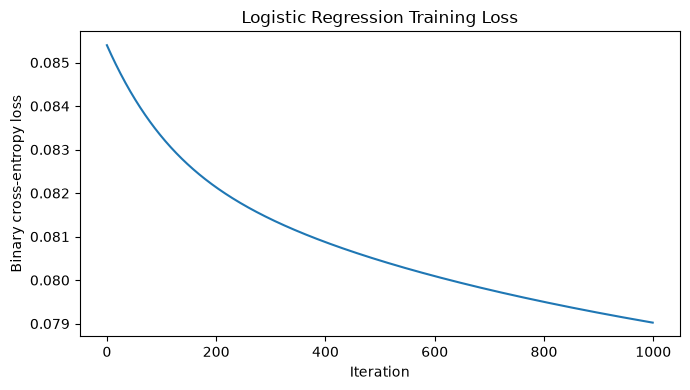

In [20]:
fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(losses)
ax.set(
    title="Logistic Regression Training Loss",
    xlabel="Iteration",
    ylabel="Binary cross-entropy loss"
)

plt.tight_layout()
fig.savefig(PROJECT_ROOT / "outputs/figures/training_loss.png", dpi=180)
plt.show()

### 5.6 Checking Convergence

The initial model reduced its training loss from 0.085398 to 0.079024, suggesting that gradient descent is working as intended.

However, training reached the maximum of 1,000 iterations. Before accepting the result, I will check whether the loss was still improving near the end of training and whether the gradients had become sufficiently small.

In [21]:
# Check whether training was still improving near the final iteration.
_, dw, db = loss_and_gradient(
    X_train, y_train,
    baseline_model["weights"],
    baseline_model["intercept"]
)

print(f"Loss reduction (last 100 iterations): {losses[-101] - losses[-1]:.8f}")
print(f"Final gradient norm: {np.linalg.norm(np.r_[dw, db]):.6f}")
print(f"Loss consistently decreased: {np.all(np.diff(losses) <= 1e-8)}")

Loss reduction (last 100 iterations): 0.00022802
Final gradient norm: 0.003297
Loss consistently decreased: True


**Findings**

The training loss decreased consistently from 0.085398 to 0.079024. Over the final 100 iterations, it improved by a further 0.000228, while the gradient norm reached 0.003297.

These results show that gradient descent is working and that improvements are becoming smaller. However, the model reached the maximum of 1,000 iterations, so I cannot conclude that it has fully converged.

I will retain this model as my initial benchmark and assess whether further training improves its performance on unseen validation data.

## 6. Model Evaluation and Improvement

The initial model reduced its training loss, but this does not yet tell me how well it identifies bestsellers in unseen data.

I will evaluate the model using the validation set before testing possible improvements. The test set will remain untouched until I have selected the final model.

Because bestsellers represent only a small proportion of the data, I will consider precision, recall, F1-score and average precision alongside accuracy.

### 6.1 Initial Validation Results

I will begin by evaluating my Logistic Regression model against a simple baseline that classifies every book as a non-bestseller.

Since only 1.68% of the training data consists of bestsellers, accuracy alone could be misleading. I will therefore examine precision, recall, F1-score, average precision and ROC-AUC.

I will also use a confusion matrix to see exactly where the model makes mistakes and whether it identifies any of the books the publisher is interested in.

Majority-class accuracy: 98.37%
Model accuracy: 98.37%
Average precision: 0.0469
ROC-AUC: 0.7370
Precision: 0.0000
Recall: 0.0000
F1-score: 0.0000


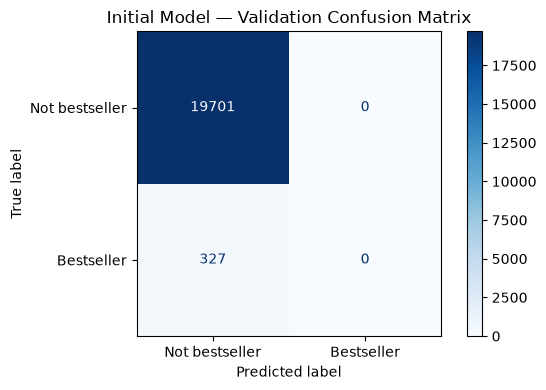

In [22]:
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_recall_fscore_support,
    ConfusionMatrixDisplay
)

# Evaluate the initial model at the default threshold.
val_scores = sigmoid(
    X_val @ baseline_model["weights"] + baseline_model["intercept"]
)
val_pred = (val_scores >= 0.5).astype(int)

precision, recall, f1, _ = precision_recall_fscore_support(
    y_val, val_pred, average="binary", zero_division=0
)

print(f"Majority-class accuracy: {(y_val == 0).mean():.2%}")
print(f"Model accuracy: {(val_pred == y_val).mean():.2%}")
print(f"Average precision: {average_precision_score(y_val, val_scores):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_val, val_scores):.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1:.4f}")

fig, ax = plt.subplots(figsize=(6, 4))

ConfusionMatrixDisplay.from_predictions(
    y_val, val_pred,
    display_labels=["Not bestseller", "Bestseller"],
    cmap="Blues",
    values_format="d",
    ax=ax
)

ax.set_title("Initial Model — Validation Confusion Matrix")
plt.tight_layout()

fig.savefig(
    PROJECT_ROOT / "outputs/figures/initial_confusion_matrix.png",
    dpi=180
)
plt.show()

**Findings**

At the default threshold of 0.5, the model achieved 98.37% accuracy but failed to identify any of the 327 bestsellers. The confusion matrix confirms that every book was classified as a non-bestseller.

However, its average precision of 0.0469 exceeds the validation bestseller rate of 1.63%, while its ROC-AUC of 0.7370 suggests some ability to distinguish the classes.

This tells me that the model has learned useful patterns, but its current classification decisions offer little value to the publisher. I will therefore investigate whether adjusting the decision threshold improves its ability to identify bestsellers before changing the training approach.

### 6.2 Adjusting the Decision Threshold

The initial model showed some ability to distinguish bestsellers, but it failed to identify any at the default threshold of 0.5.

Before changing how the model is trained, I want to see whether a different threshold can make its existing predictions more useful to the publisher.

I will use the validation set to find the threshold with the highest F1-score, then examine the precision-recall curve and confusion matrix. This will help me understand the trade-off between identifying more bestsellers and incorrectly flagging other books.

The selected threshold will serve as a starting point for comparison rather than a final business decision.

Best threshold: 0.0505
Books flagged: 315 (1.57%)
Precision: 0.1111
Recall: 0.1070
F1-score: 0.1090


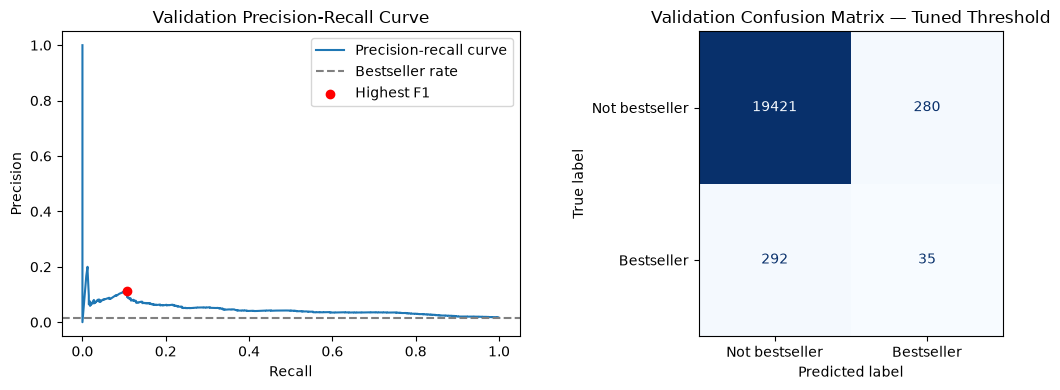

In [23]:
from sklearn.metrics import precision_recall_curve

# Find the threshold with the highest validation F1-score.
p, r, thresholds = precision_recall_curve(y_val, val_scores)
f1_scores = 2 * p[:-1] * r[:-1] / np.maximum(p[:-1] + r[:-1], 1e-12)

best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]
tuned_pred = (val_scores >= best_threshold).astype(int)

print(f"Best threshold: {best_threshold:.4f}")
print(f"Books flagged: {tuned_pred.sum():,} ({tuned_pred.mean():.2%})")
print(f"Precision: {p[best_idx]:.4f}")
print(f"Recall: {r[best_idx]:.4f}")
print(f"F1-score: {f1_scores[best_idx]:.4f}")

# Show the precision-recall trade-off and resulting predictions.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(r, p, label="Precision-recall curve")
axes[0].axhline(y_val.mean(), linestyle="--", color="grey",
                label="Bestseller rate")
axes[0].scatter(r[best_idx], p[best_idx], color="red",
                zorder=3, label="Highest F1")
axes[0].set(
    title="Validation Precision-Recall Curve",
    xlabel="Recall",
    ylabel="Precision"
)
axes[0].legend()

ConfusionMatrixDisplay.from_predictions(
    y_val, tuned_pred,
    display_labels=["Not bestseller", "Bestseller"],
    cmap="Blues",
    values_format="d",
    colorbar=False,
    ax=axes[1]
)
axes[1].set_title("Validation Confusion Matrix — Tuned Threshold")

plt.tight_layout()
fig.savefig(PROJECT_ROOT / "outputs/figures/threshold_evaluation.png", dpi=180)
plt.show()

**Findings**

Lowering the threshold from 0.5 to 0.0505 allowed the model to identify 35 of the 327 bestsellers, improving recall from 0% to 10.70%. Precision reached 11.11%, with an F1-score of 0.1090.

Although this is an improvement, the model incorrectly flagged 280 non-bestsellers and still missed 292 actual bestsellers.

The results show that adjusting the threshold makes the model more useful, but its ability to identify bestsellers remains limited. I will now investigate whether giving the minority class greater importance during training improves its performance.


### 6.3 Improving the Model with Class Weighting

Adjusting the threshold improved bestseller identification, but the model still missed most positive cases.

I will now test whether class weighting improves its ability to distinguish bestsellers. He and Garcia (2009) discuss cost-sensitive learning as one approach to handling imbalanced classification problems.

I will calculate the weights from the training data and give greater importance to errors involving bestsellers.

To make the comparison fair, I will keep the initial training settings unchanged. I will then compare both models using validation average precision and their best F1-scores.

This should help me establish whether class weighting improves the model's predictions or merely changes the balance between precision and recall.


Class weights: {0: np.float64(0.5085548742634967), 1: np.float64(29.72310630171865)}
Training iterations: 1,000
Unweighted AP: 0.0469
Weighted AP: 0.0689
Unweighted best F1: 0.1090
Weighted best F1: 0.1409
Weighted threshold: 0.8632
Weighted precision: 0.1382
Weighted recall: 0.1437


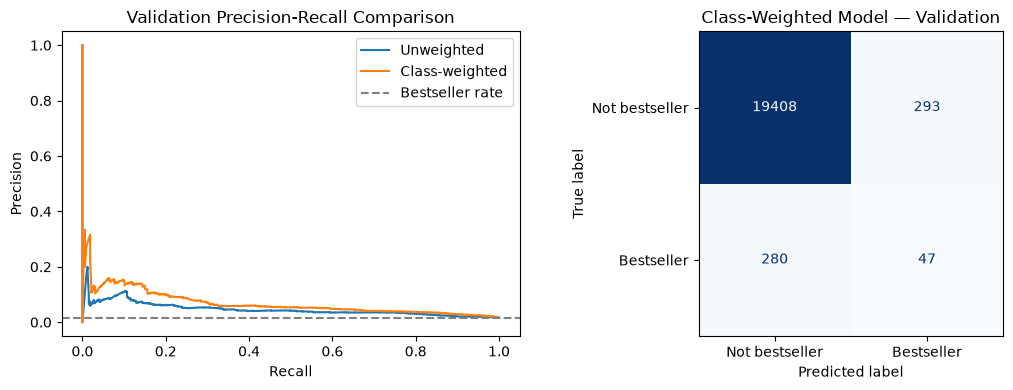

In [24]:
# Give each class equal total weight during training.
counts = np.bincount(y_train)
class_weights = {
    c: len(y_train) / (2 * counts[c]) for c in (0, 1)
}

weighted_model = train_logistic(
    X_train, y_train, class_weight=class_weights
)

weighted_scores = sigmoid(
    X_val @ weighted_model["weights"] + weighted_model["intercept"]
)

# Find the best validation threshold for the weighted model.
p_w, r_w, t_w = precision_recall_curve(y_val, weighted_scores)
f1_w = 2 * p_w[:-1] * r_w[:-1] / np.maximum(p_w[:-1] + r_w[:-1], 1e-12)

idx = np.argmax(f1_w)
weighted_threshold = t_w[idx]
weighted_pred = (weighted_scores >= weighted_threshold).astype(int)

print(f"Class weights: {class_weights}")
print(f"Training iterations: {len(weighted_model['losses']):,}")
print(f"Unweighted AP: {average_precision_score(y_val, val_scores):.4f}")
print(f"Weighted AP: {average_precision_score(y_val, weighted_scores):.4f}")
print(f"Unweighted best F1: {f1_scores[best_idx]:.4f}")
print(f"Weighted best F1: {f1_w[idx]:.4f}")
print(f"Weighted threshold: {weighted_threshold:.4f}")
print(f"Weighted precision: {p_w[idx]:.4f}")
print(f"Weighted recall: {r_w[idx]:.4f}")

# Compare ranking performance and classification errors.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(r, p, label="Unweighted")
axes[0].plot(r_w, p_w, label="Class-weighted")
axes[0].axhline(
    y_val.mean(), linestyle="--", color="grey",
    label="Bestseller rate"
)
axes[0].set(
    title="Validation Precision-Recall Comparison",
    xlabel="Recall",
    ylabel="Precision"
)
axes[0].legend()

ConfusionMatrixDisplay.from_predictions(
    y_val, weighted_pred,
    display_labels=["Not bestseller", "Bestseller"],
    cmap="Blues",
    values_format="d",
    colorbar=False,
    ax=axes[1]
)
axes[1].set_title("Class-Weighted Model — Validation")

plt.tight_layout()
fig.savefig(
    PROJECT_ROOT / "outputs/figures/class_weight_comparison.png",
    dpi=180
)
plt.show()

**Findings**

Class weighting improved average precision from 0.0469 to 0.0689 and the best validation F1-score from 0.1090 to 0.1409.

The weighted model identified 47 bestsellers, compared with 35 previously. It also incorrectly flagged 293 non-bestsellers, slightly more than the unweighted model.

The improvement in average precision suggests that weighting helped the model rank bestsellers more effectively, rather than simply changing its classification threshold.

Although the results are encouraging, the model still misses most bestsellers. I will now investigate whether L2 regularisation can improve its ability to generalise.

### 6.4 Testing L2 Regularisation

Class weighting improved the model's validation performance, but I want to establish whether controlling coefficient size can improve it further.

I will test three L2 strengths while retaining the same class weights and training settings. According to Hastie, Tibshirani and Friedman (2009), regularisation can help control model complexity and reduce overfitting.

I will compare average precision, the best validation F1-score and the size of the learned coefficients.

The aim is to establish whether regularisation improves performance on unseen data, rather than simply reducing the training loss.

In [25]:
import pandas as pd

# Compare L2 strengths while keeping other settings unchanged.
l2_models = {0.0: weighted_model}
results = []

for strength in (0.0, 0.001, 0.01, 0.1):
    model = (
        weighted_model if strength == 0
        else train_logistic(
            X_train, y_train,
            l2=strength,
            class_weight=class_weights
        )
    )

    l2_models[strength] = model

    scores = sigmoid(X_val @ model["weights"] + model["intercept"])
    precision_l2, recall_l2, _ = precision_recall_curve(y_val, scores)

    f1_l2 = (
        2 * precision_l2[:-1] * recall_l2[:-1]
        / np.maximum(precision_l2[:-1] + recall_l2[:-1], 1e-12)
    )

    results.append({
        "L2 strength": strength,
        "Average precision": average_precision_score(y_val, scores),
        "Best F1": f1_l2.max(),
        "Coefficient norm": np.linalg.norm(model["weights"]),
        "Iterations": len(model["losses"])
    })

l2_results = pd.DataFrame(results)

display(l2_results.set_index("L2 strength").round(4))

,Average precision,Best F1,Coefficient norm,Iterations
L2 strength,,,,
0.000,0.0689,0.1409,3.6611,1000
0.001,0.0681,0.1433,3.4085,1000
0.010,0.0617,0.1392,2.1399,1000
0.100,0.0413,0.0962,0.7045,335


**Findings**

Increasing L2 regularisation reduced the size of the model's coefficients, but it did not improve average precision.

The unregularised model achieved the highest average precision of 0.0689. A small penalty of 0.001 produced a slightly higher F1-score of 0.1433, although its average precision fell to 0.0681.

Stronger penalties reduced both measures, suggesting that excessive regularisation may be limiting the model's ability to distinguish bestsellers.

Since the strongest configurations reached the maximum of 1,000 iterations, I will check whether additional training changes their performance before selecting the final model.

### 6.5 Checking Training Duration

The two strongest models reached the maximum of 1,000 iterations, so their training may have stopped before the loss had settled.

I will allow these models to train for up to 2,000 iterations and compare their validation performance with the earlier results.

I will also examine whether the training loss is still improving near the end. This will help me decide whether additional training is worthwhile before selecting the final model.

In [26]:
# Check whether longer training improves the two strongest models.
longer_models = {}
training_results = []

for strength in (0.0, 0.001):
    model = train_logistic(
        X_train, y_train,
        max_iter=2000,
        l2=strength,
        class_weight=class_weights
    )

    scores = sigmoid(X_val @ model["weights"] + model["intercept"])
    p_new, r_new, _ = precision_recall_curve(y_val, scores)

    f1_new = 2 * p_new[:-1] * r_new[:-1] / np.maximum(
        p_new[:-1] + r_new[:-1], 1e-12
    )

    longer_models[strength] = model

    training_results.append({
        "L2 strength": strength,
        "Iterations": len(model["losses"]),
        "Average precision": average_precision_score(y_val, scores),
        "Best F1": f1_new.max(),
        "Last 100 loss reduction":
            model["losses"][-101] - model["losses"][-1]
    })

display(
    pd.DataFrame(training_results)
    .set_index("L2 strength")
    .round(6)
)

,Iterations,Average precision,Best F1,Last 100 loss reduction
L2 strength,,,,
0.000,2000,0.068590,0.144427,0.000296
0.001,2000,0.068711,0.143750,0.000131


**Findings**

Increasing the training limit to 2,000 iterations produced small improvements in the best F1-scores, but neither model exceeded the original class-weighted model's average precision of 0.0689.

Both models were still reducing their training losses after 2,000 iterations, so I cannot claim that they had fully converged.

Since average precision is my primary measure for identifying the relatively rare bestseller class, I will retain the class-weighted model trained for 1,000 iterations without L2 regularisation.

The differences are small, so this is a practical model-selection decision rather than evidence that additional training would never help.

### 6.6 Final Model Evaluation

The validation experiments showed that class weighting improved the model's ability to distinguish bestsellers, while L2 regularisation and additional training offered no clear improvement in average precision.

I have selected the class-weighted model trained for 1,000 iterations without regularisation. I will use its validation-selected threshold of 0.8632.

I will now evaluate this configuration on the untouched test set to establish whether its performance holds beyond the data used for model selection.

Alongside average precision and ROC-AUC, I will report the classification metrics and confusion matrix. This will show how many bestsellers the model identifies and how many books the publisher would need to review.

Decision threshold: 0.8632
Majority-class accuracy: 98.28%
Model accuracy: 97.01%
Average precision: 0.0665
ROC-AUC: 0.8039
Books flagged: 331

                precision    recall  f1-score   support

Not bestseller       0.98      0.98      0.98     19346
    Bestseller       0.12      0.12      0.12       338

      accuracy                           0.97     19684
     macro avg       0.55      0.55      0.55     19684
  weighted avg       0.97      0.97      0.97     19684



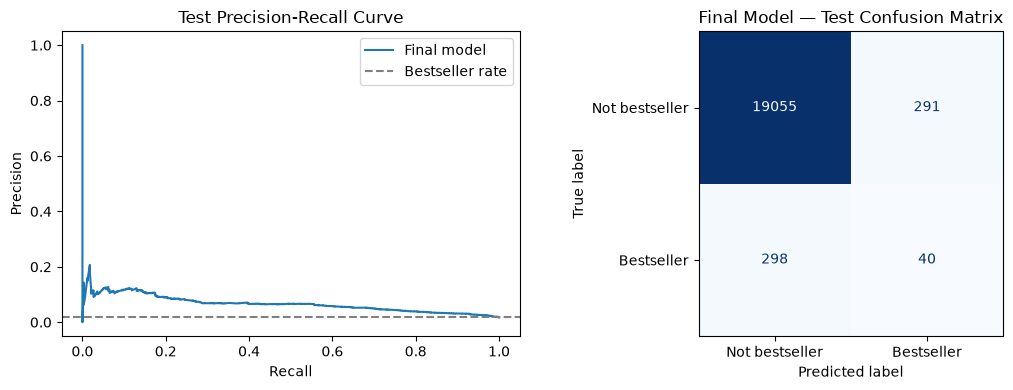

In [27]:
from sklearn.metrics import classification_report

# Lock the model and threshold selected using validation data.
final_model = weighted_model
final_threshold = weighted_threshold

test_scores = sigmoid(
    X_test @ final_model["weights"] + final_model["intercept"]
)
test_pred = (test_scores >= final_threshold).astype(int)

print(f"Decision threshold: {final_threshold:.4f}")
print(f"Majority-class accuracy: {(y_test == 0).mean():.2%}")
print(f"Model accuracy: {(test_pred == y_test).mean():.2%}")
print(f"Average precision: {average_precision_score(y_test, test_scores):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, test_scores):.4f}")
print(f"Books flagged: {test_pred.sum():,}\n")

print(classification_report(
    y_test, test_pred,
    target_names=["Not bestseller", "Bestseller"],
    zero_division=0
))

# Show the final ranking performance and classification errors.
test_p, test_r, _ = precision_recall_curve(y_test, test_scores)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(test_r, test_p, label="Final model")
axes[0].axhline(
    y_test.mean(), color="grey", linestyle="--",
    label="Bestseller rate"
)
axes[0].set(
    title="Test Precision-Recall Curve",
    xlabel="Recall",
    ylabel="Precision"
)
axes[0].legend()

ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred,
    display_labels=["Not bestseller", "Bestseller"],
    cmap="Blues", values_format="d",
    colorbar=False, ax=axes[1]
)
axes[1].set_title("Final Model — Test Confusion Matrix")

plt.tight_layout()
fig.savefig(
    PROJECT_ROOT / "outputs/figures/final_model_evaluation.png",
    dpi=180
)
plt.show()

**Findings**

The final model achieved an average precision of 0.0665 and ROC-AUC of 0.8039 on the independent test set. Its average precision was close to the validation result of 0.0689, suggesting that its ranking performance remained reasonably consistent.

At the selected threshold, the model identified 40 of the 338 bestsellers, giving a recall of 11.83% and precision of 12.08%. However, it also incorrectly flagged 291 non-bestsellers and missed 298 actual bestsellers.

Although the model identified more bestsellers than the majority-class baseline, its accuracy of 97.01% was lower than the baseline's 98.28%. This reinforces why accuracy alone is not suitable for evaluating this problem.

The results show that the model has learned some useful relationships, but its ability to identify bestsellers remains limited. I would therefore consider it an experimental screening tool rather than a reliable basis for publishing decisions.

## 7. Conclusions and Limitations

The aim of this investigation was to determine whether Logistic Regression could help a publisher identify books associated with bestseller success.

I developed the algorithm from scratch, investigated the available book characteristics and tested several ways of improving its performance. The EDA showed that category, price, publication year and Kindle Unlimited availability were associated with bestseller status. Class weighting provided the clearest improvement during model development.

On the independent test set, the final model achieved an average precision of 0.0665 and ROC-AUC of 0.8039. It correctly identified 40 of the 338 bestsellers, but missed 298 and incorrectly flagged another 291 books.

These results suggest that the model has learned useful patterns, but its practical value remains limited. It could help the publisher narrow down books for further investigation, although its predictions would not be reliable enough to guide major publishing decisions independently.

### Limitations and Future Improvements

The biggest limitation is the dataset itself. Bestseller status was recorded at collection time, so I cannot establish whether the model would correctly predict future success. Recorded prices and Kindle Unlimited availability may also have changed after publication.

The dataset is heavily imbalanced, and missing publication dates further limit the information available for training. Although I kept related title-author listings together during data splitting, this does not guarantee that every related edition was identified.

A stronger approach would use historical sales records and book characteristics captured before publication, followed by evaluation on books released during a later period.

Overall, I have demonstrated that Logistic Regression can identify some meaningful differences between bestsellers and other books. However, answering the publisher's original question with greater confidence would require better historical data and further validation.

## 8. References

Amazon Kindle Direct Publishing, n.d. KDP Select. [online] Available at: https://kdp.amazon.com/en_US/help/topic/G200798990 [Accessed 21 October 2026].

asaniczka, 2023. Amazon Kindle Books Dataset 2023 (130K Books). [online] Available at: https://www.kaggle.com/datasets/asaniczka/amazon-kindle-books-dataset-2023-130k-books [Accessed 21 October 2026].

Bishop, C.M., 2006. Pattern recognition and machine learning. [e-book] New York: Springer. Available at: https://www.microsoft.com/en-us/research/wp-content/uploads/2006/01/Bishop-Pattern-Recognition-and-Machine-Learning-2006.pdf [Accessed 21 October 2026].

Hastie, T., Tibshirani, R. and Friedman, J., 2009. The elements of statistical learning: Data mining, inference, and prediction. 2nd ed. [e-book] New York: Springer. Available at: https://doi.org/10.1007/978-0-387-84858-7 [Accessed 21 October 2026].

He, H. and Garcia, E.A., 2009. Learning from imbalanced data. IEEE Transactions on Knowledge and Data Engineering, [e-journal] 21(9), pp.1263–1284. Available at: https://doi.org/10.1109/TKDE.2008.239 [Accessed 21 October 2026].

Kaufman, S., Rosset, S., Perlich, C. and Stitelman, O., 2012. Leakage in data mining: Formulation, detection, and avoidance. ACM Transactions on Knowledge Discovery from Data, [e-journal] 6(4), article 15, pp.1–21. Available at: https://doi.org/10.1145/2382577.2382579 [Accessed 21 October 2026].

Kuhn, M. and Johnson, K., 2019. Feature engineering and selection: A practical approach for predictive models. [e-book] Boca Raton: Chapman & Hall/CRC. Available at: https://doi.org/10.1201/9781315108230 [Accessed 21 October 2026].

Saito, T. and Rehmsmeier, M., 2015. The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. PLOS ONE, [e-journal] 10(3), e0118432. Available at: https://doi.org/10.1371/journal.pone.0118432 [Accessed 21 October 2026].

Schmidt-Stölting, C., Blömeke, E. and Clement, M., 2011. Success drivers of fiction books: An empirical analysis of hardcover and paperback editions in Germany. Journal of Media Economics, [e-journal] 24(1), pp.24–47. Available at: https://doi.org/10.1080/08997764.2011.549428 [Accessed 21 October 2026].

Yucesoy, B., Wang, X., Huang, J. and Barabási, A.-L., 2018. Success in books: A big data approach to bestsellers. EPJ Data Science, [e-journal] 7(1), article 7. Available at: https://doi.org/10.1140/epjds/s13688-018-0135-y [Accessed 21 October 2026].

### AI Assistance and Acknowledgement

AI tools, including ChatGPT (OpenAI, 2026), were used to support research, coding, troubleshooting and documentation during this project.

AI-generated suggestions and contributions were reviewed, tested and incorporated where appropriate. Responsibility for the final implementation, analysis, interpretation and conclusions remains with the author.